In [2]:
import pandas as pd
from sqlalchemy import create_engine

# 1. Connect to your local MySQL database (olist_db)
db_user = 'root'
db_password = 'admin54321'  # Put your MySQL password here
db_host = 'localhost'
db_port = '3306'
db_name = 'olist_db'

connection_string = (
    f'mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}'
)
engine = create_engine(connection_string)

# 2. Write a SQL query to check your customers table
query = """
    SELECT customer_id, customer_state 
    FROM customers 
    LIMIT 5;
"""

# 3. Load results directly into a Pandas DataFrame
df = pd.read_sql(query, con=engine)

# 4. Display the table
print(df)

                        customer_id customer_state
0  06b8999e2fba1a1fbc88172c00ba8bc7             SP
1  18955e83d337fd6b2def6b18a428ac77             SP
2  4e7b3e00288586ebd08712fdd0374a03             SP
3  b2b6027bc5c5109e529d4dc6358b12c3             SP
4  4f2d8ab171c80ec8364f7c12e35b23ad             SP


In [3]:
import pandas as pd
from sqlalchemy import URL, create_engine

url_object = URL.create(
    'mysql+pymysql',
    username='root',
    password='admin54321',  # Update with your password
    host='127.0.0.1',
    port=3306,
    database='olist_db',
)
engine = create_engine(url_object)

# Check columns of customers table
schema_query = 'DESCRIBE customers;'
print(pd.read_sql(schema_query, con=engine))

                      Field  Type Null Key Default Extra
0               customer_id  text  YES        None      
1        customer_unique_id  text  YES        None      
2  customer_zip_code_prefix  text  YES        None      
3             customer_city  text  YES        None      
4            customer_state  text  YES        None      


In [4]:
import pandas as pd
from sqlalchemy import URL, create_engine

# 1. Connect to your database
url_object = URL.create(
    'mysql+pymysql',
    username='root',
    password='admin54321',  # Replace with your actual password
    host='127.0.0.1',
    port=3306,
    database='olist_db',
)
engine = create_engine(url_object)

# 2. Updated RFM SQL query using customer_id and the 2018 snapshot date
rfm_query = """
    SELECT 
        c.customer_id,
        -- Recency: Days between last purchase and your dataset's latest date ('2018-08-30')
        DATEDIFF('2018-08-30', MAX(o.order_purchase_timestamp)) AS recency,
        
        -- Frequency: Total number of orders placed by the customer
        COUNT(DISTINCT o.order_id) AS frequency,
        
        -- Monetary: Total spend (price + freight) across all delivered orders
        SUM(oi.price + oi.freight_value) AS monetary
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_id;
"""

# 3. Load directly into a Pandas DataFrame
rfm_df = pd.read_sql(rfm_query, con=engine)

# 4. Preview the first 5 rows and check dataframe dimensions
print(rfm_df.head())
print('\nDataset Shape:', rfm_df.shape)

                        customer_id  recency  frequency  monetary
0  00012a2ce6f8dcda20d059ce98491703      289          1    114.74
1  000161a058600d5901f007fab4c27140      410          1     67.41
2  0001fd6190edaaf884bcaf3d49edf079      548          1    195.42
3  0002414f95344307404f0ace7a26f1d5      379          1    179.35
4  000379cdec625522490c315e70c7a9fb      150          1    107.01

Dataset Shape: (96478, 4)


In [5]:
from sklearn.preprocessing import StandardScaler

# 1. Select the RFM columns for clustering (exclude customer_id)
X = rfm_df[['recency', 'frequency', 'monetary']]

# 2. Initialize the StandardScaler to normalize our features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Preview the scaled data
print('First 5 rows of scaled RFM features:')
print(X_scaled[:5])

First 5 rows of scaled RFM features:
[[ 0.31629574  0.         -0.20607068]
 [ 1.10797658  0.         -0.42239378]
 [ 2.01088531  0.          0.16267955]
 [ 0.90514926  0.          0.08923116]
 [-0.59315581  0.         -0.24140086]]


Total customers available for clustering: 96478


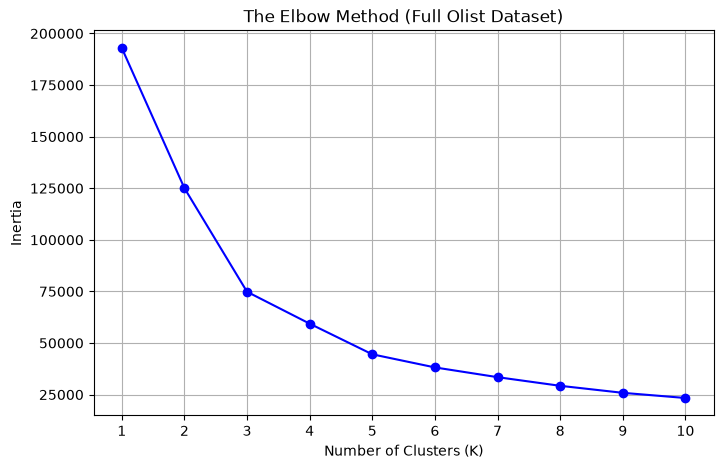

In [6]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Dynamically set K range based on your number of samples
n_samples = len(X_scaled)
print(f'Total customers available for clustering: {n_samples}')

# K must be strictly less than the number of samples
max_k = min(11, n_samples)
K_range = range(1, max_k)

inertia = []

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

# 2. Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method (Full Olist Dataset)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

In [7]:
from sklearn.cluster import KMeans

# 1. Choose your optimal K
optimal_k = 5

# 2. Run K-Means with the chosen K
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# 3. Add the cluster labels back to your original DataFrame
rfm_df['Cluster'] = cluster_labels

# 4. View your segmented customers!
print(rfm_df.head(10))

                        customer_id  recency  frequency  monetary  Cluster
0  00012a2ce6f8dcda20d059ce98491703      289          1    114.74        2
1  000161a058600d5901f007fab4c27140      410          1     67.41        1
2  0001fd6190edaaf884bcaf3d49edf079      548          1    195.42        1
3  0002414f95344307404f0ace7a26f1d5      379          1    179.35        1
4  000379cdec625522490c315e70c7a9fb      150          1    107.01        0
5  0004164d20a9e969af783496f3408652      505          1     71.80        1
6  000419c5494106c306a97b5635748086      181          1     49.40        2
7  00046a560d407e99b969756e0b10f282      255          1    166.59        2
8  00050bf6e01e69d5c0fd612f1bcfb69c      347          1     85.23        2
9  000598caf2ef4117407665ac33275130       19          1   1255.71        4


In [8]:
# View average metrics and size for each of the 5 clusters
cluster_profile = (
    rfm_df.groupby('Cluster')
    .agg(
        {
            'recency': 'mean',
            'frequency': 'mean',
            'monetary': ['mean', 'count'],
        }
    )
    .round(2)
)

print(cluster_profile)

        recency frequency monetary       
           mean      mean     mean  count
Cluster                                  
0         87.91       1.0   124.08  34619
1        459.18       1.0   124.88  22057
2        256.00       1.0   118.35  34569
3        239.74       1.0  1928.23    627
4        227.19       1.0   666.43   4606


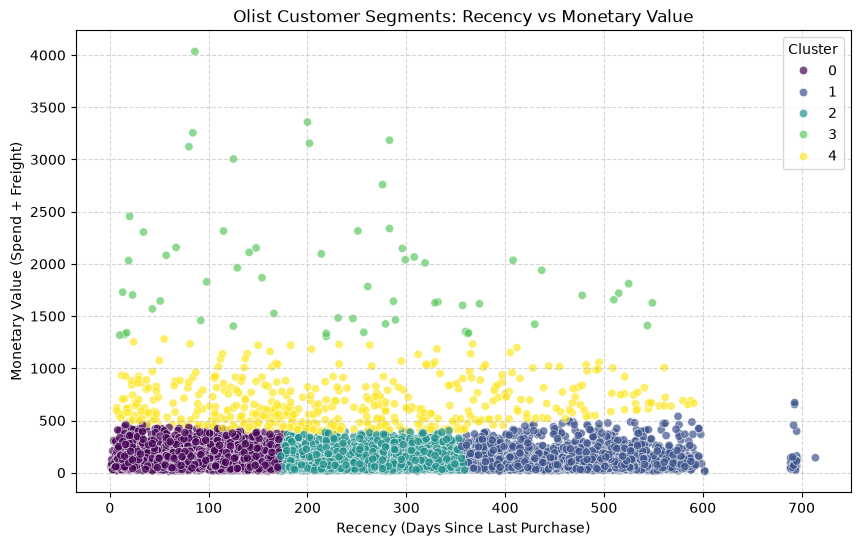

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
# Using a sample of the data if it's too large to plot efficiently
plot_df = rfm_df.sample(n=min(10000, len(rfm_df)), random_state=42)

sns.scatterplot(
    data=plot_df,
    x="recency",
    y="monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7,
)

plt.title("Olist Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Monetary Value (Spend + Freight)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [10]:
import pandas as pd
from sqlalchemy import create_engine, URL

# 1. Export to CSV file
print("Exporting customer segments to CSV...")
rfm_df.to_csv("olist_customer_segments.csv", index=False)
print("Successfully saved as 'olist_customer_segments.csv'!")

# 2. Export back into MySQL database (olist_db)
print("\nSaving customer segments back to MySQL...")
url_object = URL.create(
    "mysql+pymysql",
    username="root",
    password="admin54321",  # Replace with your actual password
    host="127.0.0.1",
    port=3306,
    database="olist_db"
)
engine = create_engine(url_object)

# Write dataframe to a new MySQL table named 'customer_segments'
rfm_df.to_sql("customer_segments", con=engine, if_exists="replace", index=False)
print("Successfully saved customer segments to MySQL table 'customer_segments'!")

Exporting customer segments to CSV...
Successfully saved as 'olist_customer_segments.csv'!

Saving customer segments back to MySQL...
Successfully saved customer segments to MySQL table 'customer_segments'!
